In [39]:
# Data Analysis Project
## Weather conditions and accident severity in France (ONISR 2018)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
carac = pd.read_csv("ACC-caracteristiques-2018.csv", sep=",", encoding="utf-8")
lieux = pd.read_csv("ACC-lieux-2018.csv", sep=",", encoding="utf-8")
usagers = pd.read_csv("ACC-usagers-2018.csv", sep=",", encoding="utf-8")
vehicules = pd.read_csv("ACC-vehicules-2018.csv", sep=",", encoding="utf-8")

NameError: name 'pd' is not defined

In [42]:
print("carac columns:")
print(carac.columns.tolist())

print("usagers columns:")
print(usagers.columns.tolist())

print("lieux columns:")
print(lieux.columns.tolist())

carac columns:
['Num_Acc', 'an', 'mois', 'jour', 'hrmn', 'lum', 'agg', 'int', 'atm', 'col', 'com', 'adr', 'gps', 'lat', 'long', 'dep']
usagers columns:
['Num_Acc', 'place', 'catu', 'grav', 'sexe', 'trajet', 'secu', 'locp', 'actp', 'etatp', 'an_nais', 'num_veh']
lieux columns:
['Num_Acc', 'catr', 'voie', 'v1', 'v2', 'circ', 'nbv', 'pr', 'pr1', 'vosp', 'prof', 'plan', 'lartpc', 'larrout', 'surf', 'infra', 'situ', 'env1']


In [43]:
df = carac[["Num_Acc", "atm", "hrmn"]].copy()

df = df.merge(
    usagers[["Num_Acc", "grav", "an_nais", "catu"]],
    on="Num_Acc",
    how="left"
)

df = df.merge(
    lieux[["Num_Acc", "vosp"]],
    on="Num_Acc",
    how="left"
)

In [44]:
df["hrmn"] = df["hrmn"].astype(str).str.extract(r"(\d+)", expand=False)
df["hrmn"] = df["hrmn"].str.zfill(4)
df["hour"] = df["hrmn"].str[:2].astype(float)

In [45]:
df["age"] = 2018-df["an_nais"]
df.loc[(df["age"] < 0) | (df["age"] > 110), "age"] = np.nan
df["severe"]=df["grav"].isin([2,3])
df_weather = df.dropna(subset=["atm", "grav"])

In [46]:
df_weather["catu"] = df_weather["catu"].astype("Int64")

In [47]:
#labels

atm_labels = {
    1: "Clear",
    2: "Light rain",
    3: "Heavy rain",
    4: "Snow / hail",
    5: "Fog / smoke",
    6: "Strong wind",
    7: "Dazzling weather",
    8: "Overcast",
    9: "Other"
}

catu_labels = {
    1: "Driver",
    2: "Passenger",
    3: "Pedestrian"
}

df_weather["atm_label"] = df_weather["atm"].map(atm_labels).fillna("Unknown")
df_weather["catu_label"] = df_weather["catu"].map(catu_labels).fillna("Unknown")

In [48]:
## Visualization 1 — Weather conditions and accident severity

In [49]:
weather_analysis = (
    df_weather.groupby("atm_label")
    .agg(
        n=("Num_Acc", "size"),
        severe_rate=("severe", "mean")
    )
    .sort_values("n", ascending=False)
)

print(weather_analysis)

                       n  severe_rate
atm_label                            
Clear             103511     0.195061
Light rain         13985     0.176546
Overcast            4486     0.195720
Heavy rain          3111     0.212472
Dazzling weather    2360     0.274153
Fog / smoke          945     0.323810
Snow / hail          895     0.167598
Other                611     0.289689
Strong wind          256     0.312500


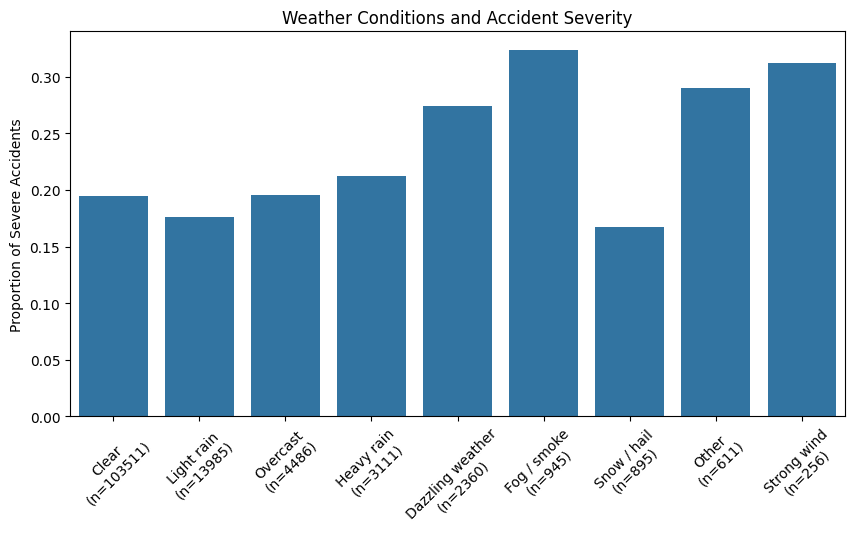

In [50]:
labels = [
    f"{cond}\n(n={weather_analysis.loc[cond, 'n']})"
    for cond in weather_analysis.index
]

plt.figure(figsize=(10,5))

sns.barplot(
    x=labels,
    y=weather_analysis["severe_rate"]
)

plt.title("Weather Conditions and Accident Severity")
plt.ylabel("Proportion of Severe Accidents")

plt.xticks(rotation=45)

plt.show()

In [51]:
## Visualization 2 — Severity throughout the day

In [52]:
hour_analysis = (
    df_weather.groupby("hour")
    .agg(severe_rate=("severe", "mean"))
    .reset_index()
)
print(hour_analysis)

    hour  severe_rate
0    0.0     0.222620
1    1.0     0.244856
2    2.0     0.292915
3    3.0     0.298039
4    4.0     0.305013
5    5.0     0.275083
6    6.0     0.248238
7    7.0     0.196272
8    8.0     0.152527
9    9.0     0.162963
10  10.0     0.193683
11  11.0     0.187887
12  12.0     0.181997
13  13.0     0.180307
14  14.0     0.187848
15  15.0     0.199462
16  16.0     0.204939
17  17.0     0.184560
18  18.0     0.192062
19  19.0     0.190961
20  20.0     0.204082
21  21.0     0.203248
22  22.0     0.217615
23  23.0     0.214760


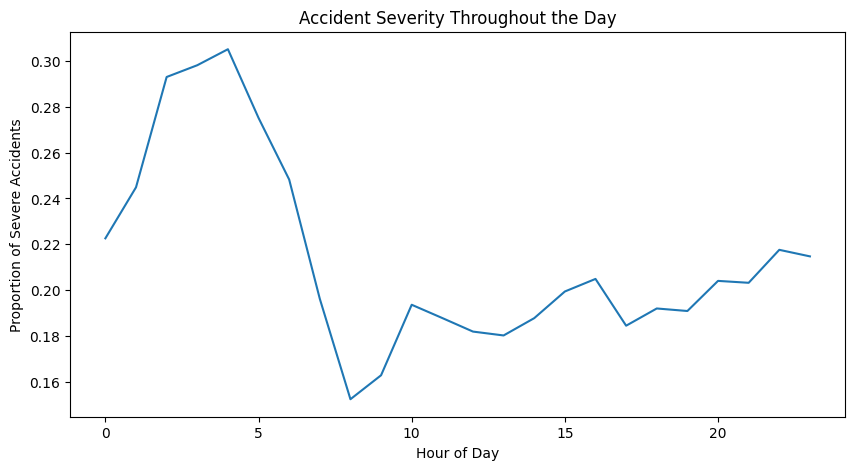

In [53]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=hour_analysis,
    x="hour",
    y="severe_rate"
)

plt.title("Accident Severity Throughout the Day")
plt.xlabel("Hour of Day")
plt.ylabel("Proportion of Severe Accidents")

plt.show()

In [54]:
## Visualization 3 — Severity by type of road user

In [63]:
user_analysis = (
    df_weather.groupby("catu")
    .agg(
        n=("Num_Acc", "size"),
        severe_rate=("severe", "mean")
    )
    .reset_index()
)

user_analysis["catu_label"] = user_analysis["catu"].map(catu_labels)


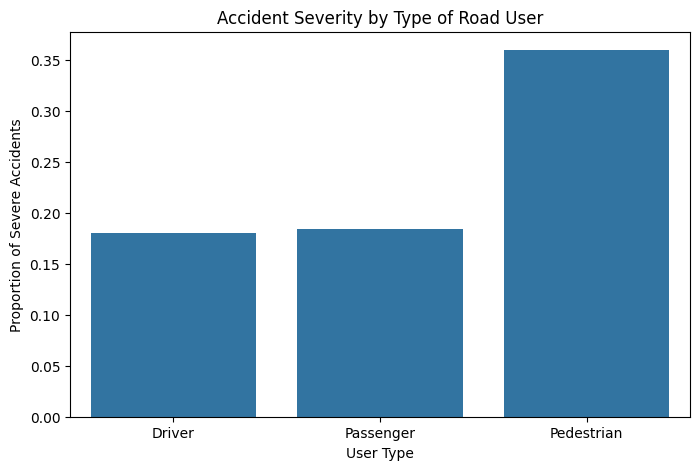

In [62]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=user_analysis["catu_label"],
    y=user_analysis["severe_rate"]
)

plt.title("Accident Severity by Type of Road User")
plt.xlabel("User Type")
plt.ylabel("Proportion of Severe Accidents")

plt.show()

In [ ]:
## Visualization 4 — Severity by weather condition and road user type

In [ ]:
df_user_weather = df_weather.dropna(subset=["atm_label", "catu_label"]).copy()

user_weather_analysis = (
    df_user_weather.groupby(["atm_label", "catu_label"])
    .agg(
        n=("Num_Acc", "size"),
        severe_rate=("severe", "mean")
    )
    .reset_index()
)

main_weather = ["Clear", "Light rain", "Fog / smoke", "Overcast"]

filtered_user_weather = user_weather_analysis[
    user_weather_analysis["atm_label"].isin(main_weather)
]

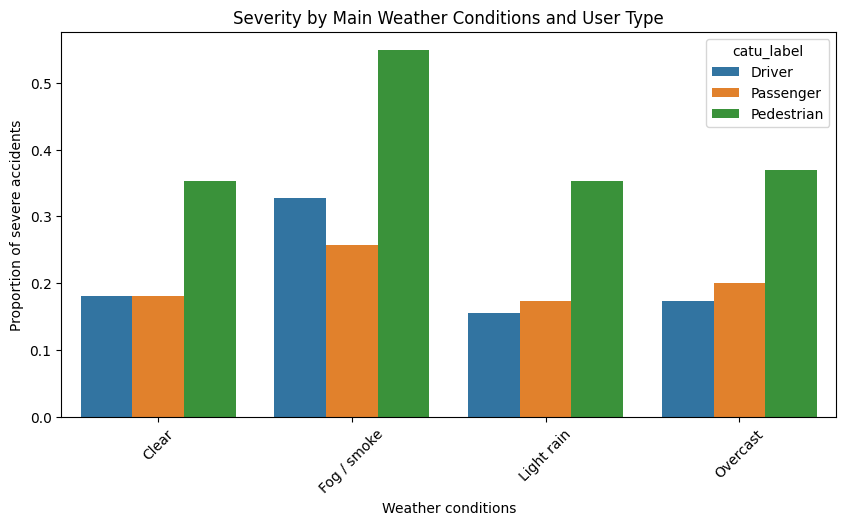

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=filtered_user_weather,
    x="atm_label",
    y="severe_rate",
    hue="catu_label"
)

plt.title("Severity by Main Weather Conditions and User Type")
plt.xlabel("Weather conditions")
plt.ylabel("Proportion of severe accidents")
plt.xticks(rotation=45)

plt.show()